# 10d - Ajout des données de pollens

Source : RNSA, « Données historiques de surveillance des pollens et des moisissures » (data.gouv.fr), dossier BDD_daily.
Modèle de départ : régression linéaire du notebook 10 (43 variables), cible TousAge_allergie_urgences.

1. Exploration des données
2. NaN 
3. Trois façons de les remplacer : A. par 0 / B. par le capteur le plus proche / C. par la médiane
4. Est ce que les données de pollens améliorent notre modèle ?
5. Conclusion

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# pour masquer les avertissements d'openpyxl
import warnings
warnings.filterwarnings("ignore")

## 1. Exploration

### Fichiers de données de pollens

In [2]:
dossier = "../data/raw/Pollen/BDD_daily 2/BDD_daily/"
fichiers = sorted(glob.glob(dossier + "*"))
print(len(fichiers), "fichiers")

# code du capteur et année
infos = []
for f in fichiers:
    nom = os.path.basename(f)
    morceaux = nom.replace("Particle_Extract_", "").split("_")
    infos.append({"code": morceaux[0], "annee": int(morceaux[1][:4]), "nom": nom, "chemin": f})
infos = pd.DataFrame(infos)

print(infos["code"].nunique(), "capteurs, de", infos["annee"].min(), "à", infos["annee"].max())

2207 fichiers
130 capteurs, de 1987 à 2024


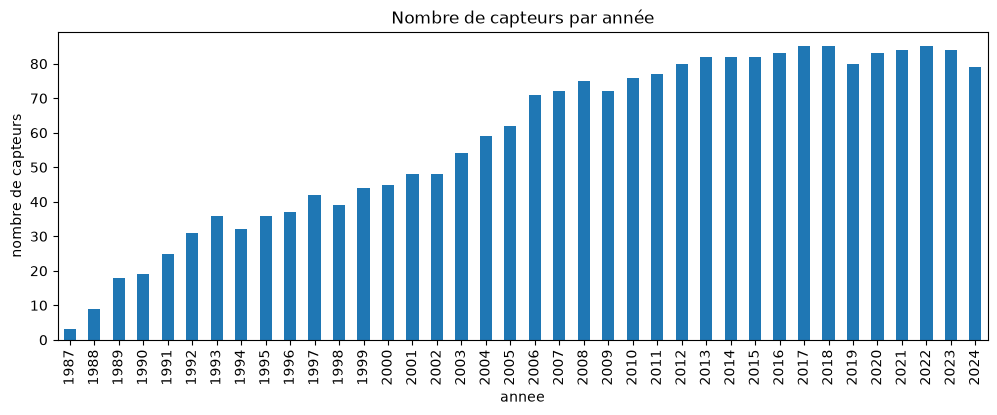

In [3]:
infos.groupby("annee")["code"].nunique().plot(kind="bar", figsize=(12, 4))
plt.ylabel("nombre de capteurs")
plt.title("Nombre de capteurs par année")
plt.show()

Un fichier par capteur et par année. Les mesures commencent en 1987, avec de plus en plus de capteurs (environ 80 par an depuis 2012).

Nos données de santé vont de 2021 à 2024, mais 2021 ne sert pas : an_dernier (même semaine un an plus tôt) y est vide, et ces lignes disparaissent au dropna, comme dans le notebook 10. Je garde donc 2022 à 2024.

In [4]:
infos = infos[infos["annee"] >= 2022]
print(len(infos), "fichiers,", infos["code"].nunique(), "capteurs")

251 fichiers, 93 capteurs


Les coordonnées des capteurs sont dans un autre fichier, où chaque capteur est écrit avec le nom de sa ville :

In [5]:
gps = pd.read_excel("../data/raw/Pollen/liste-des-stations-de-mesures-pollen-coordonnees-gps.xlsx")
print(gps.shape)
gps.head()

(130, 5)


,Stations,Latitude,Longitude,Altitude,Hauteur par rapport au sol
0,Agen,44.1941,0.6253,50.0,25.0
1,Aix-en-Provence,43.5352,5.4416,180.0,20.0
2,Ajaccio,41.9376,8.7389,6.0,35.0
3,Ales,44.1274,4.0790,134.0,NaN
4,Amberieu,45.9617,5.3557,270.0,7.0


Attention :
- dans les fichiers de pollens, le capteur apparaît sous forme d'un code (ex : AIXENPRO), sans département ni coordonnées
- dans le fichier GPS, il est écrit avec le nom de sa ville (ex : Aix-en-Provence), avec ses coordonnées mais sans département
- dans notre fichier commun (Merge_final_2), les données sont par département (ex : 13)

Pour relier les pollens à nos données, il fallait donc une table de correspondance.
C'est une tâche pratique, sans analyse, qui consiste juste à faire correspondre des noms. J'ai utilisé Claude pour l'écrire : c'est plus rapide, et ça limite les fautes de frappe qu'on ferait en recopiant 92 lignes à la main.


In [6]:
# code du fichier : (nom dans la liste GPS, département)
stations = {
    "AGEN": ("Agen", "47"),
    "AIXENPRO": ("Aix-en-Provence", "13"),
    "AJACCIO": ("Ajaccio", "2A"),
    "AMBERIEU": ("Amberieu", "01"),
    "AMIENS": ("Amiens", "80"),
    "ANGERS": ("Angers", "49"),
    "ANGOULEM": ("Angouleme", "16"),
    "ANNECY": ("Annecy", "74"),
    "ANNEMASS": ("Annemasse", "74"),
    "ANTONY": ("Antony", "92"),
    "AURILLAC": ("Aurillac", "15"),
    "AVIGNON": ("Avignon", "84"),
    "BAGNOLS": ("Bagnols", "30"),
    "BART": ("Bart", "25"),
    "BERRIAS": ("Berrias", "07"),
    "BESANCON": ("Besancon", "25"),
    "BLETTERA": ("Bletterans", "39"),
    "BORDPESS": ("Bordeaux-Pessac", "33"),
    "BOURGENB": ("Bourg en Bresse", "01"),
    "BOURGES": ("Bourges", "18"),
    "BOURGOIN": ("Bourgoin-Jallieu", "38"),
    "BREST": ("Brest reg", "29"),
    "BRUSSLAN": ("Brussieu Lanzoni", "69"),
    "CAEN": ("Caen", "14"),
    "CASTRES": ("Castres", "81"),
    "CHALON-S": ("Chalon-sur-Saone", "71"),
    "CHAMBERY": ("Chambery", "73"),
    "CHARLEVI": ("Charleville", "08"),
    "CHAUMONT": ("Chaumont", "52"),
    "CHOLET": ("Cholet", "49"),
    "CLERMONT": ("Clermont-Ferrand", "63"),
    "DIJON": ("Dijon", "21"),
    "DINAN": ("Dinan", "22"),
    "DOLE": ("Dole", "39"),
    "DRAGUIGN": ("Draguignan", "83"),
    "GAP": ("Gap", "05"),
    "GENAS": ("Genas", "69"),
    "GLEIZE": ("Gleize", "69"),
    "GONESSE": ("Gonesse", "95"),
    "GRENOBLE": ("Grenoble", "38"),
    "LAROCHE-": ("Laroche-sur-Yon", "85"),
    "LAROCHL": ("La Rochelle", "17"),
    "LEMANS": ("Le Mans", "72"),
    "LEPUYENV": ("Le Puy en Velay", "43"),
    "LILLE": ("Lille", "59"),
    "LIMOGES": ("Limoges", "87"),
    "LORIENT": ("Lorient", "56"),
    "LURE": ("Lure", "70"),
    "LYON": ("Lyon", "69"),
    "MACON": ("Macon", "71"),
    "MAREUIL": ("Mareuil", "24"),
    "MARSEILL": ("Marseille", "13"),
    "METZ": ("Metz", "57"),
    "MONTLUCO": ("Montlucon", "03"),
    "MONTPELL": ("Montpellier", "34"),
    "MTMARSAN": ("Mont-de-Marsan", "40"),
    "MULHOUSE": ("Mulhouse", "68"),
    "NANCY": ("Nancy", "54"),
    "NANTES": ("Nantes", "44"),
    "NARBONNE": ("Narbonne", "11"),
    "NEVERS": ("Nevers", "58"),
    "NICE": ("Nice", "06"),
    "NICE2": ("Nice 2", "06"),
    "NIORT": ("Niort", "79"),
    "ORLEANS": ("Orleans", "45"),
    "PARIS": ("Paris", "75"),
    "PERIGUEU": ("Perigeux", "24"),
    "PERPIGNA": ("Perpignan", "66"),
    "POITIERS": ("Poitiers", "86"),
    "PONTIVY": ("Pontivy", "56"),
    "REIMS": ("Reims", "51"),
    "RENNES": ("Rennes", "35"),
    "ROANNE": ("Roanne", "42"),
    "ROUEN": ("Rouen", "76"),
    "ROUSSILL": ("Roussillon", "38"),
    "SACLAY": ("Saclay", "91"),
    "SAINT-ET": ("Saint-Etienne", "42"),
    "SAINTDIE": ("Saint-Dié des Vosges", "88"),
    "SEDAN": ("Sedan", "08"),
    "ST-BRIEU": ("Saint-Brieuc", "22"),
    "STALBAN": ("Saint-Alban-Auriolles", "07"),
    "STRASBOU": ("Strasbourg", "67"),
    "TOULON": ("Toulon", "83"),
    "TOULOUSE": ("Toulouse", "31"),
    "TOULOUSM": ("Toulouse 2", "31"),
    "TOURS": ("Tours", "37"),
    "TROYES": ("Troyes", "10"),
    "TULLE": ("Tulle", "19"),
    "VALDAHON": ("Valdahon", "25"),
    "VALENCE": ("Valence", "26"),
    "VICHY": ("Vichy", "03"),
    "VILLENEU": ("Villeneuve d'Ascq", "59"),
}

In [7]:
# capteurs du dossier (2022-2024) qui ne sont pas dans la table de correspondance
print(sorted(set(infos["code"]) - set(stations)))

# capteurs avec deux fichiers pour la même année
infos[infos.duplicated(subset=["code", "annee"], keep=False)][["nom"]]

['ANDORRA']


,nom
132,Particle_Extract_AMIENS_2024-01-01_to_2024-06-...
133,Particle_Extract_AMIENS_2024-01-01_to_2024-12-...
1115,Particle_Extract_LILLE_2022-01-01_to_2022-10-3...
1116,Particle_Extract_LILLE_2022-01-01_to_2022-12-3...
1726,Particle_Extract_POITIERS_2024-01-01_to_2024-1...
1727,Particle_Extract_POITIERS_2024-01-01_to_2024-1...


Trois capteurs ont deux fichiers pour la même année :
- Versions incomplètes:
 AMIENS 2024 et LILLE 2022 : un fichier pour l'année entière (nom qui finit par « 12-31 ») et un fichier plus court (jusqu'au 1er juin pour Amiens, jusqu'au 31 octobre pour Lille)
- Doublon:
 POITIERS 2024 : deux fois le même fichier, le second porte « (1) » à la fin de son nom (fichier téléchargé deux fois)

In [8]:
# enlève ANDORRA
garder = infos[infos["code"].isin(stations.keys())]
# enlève fichier incomplets ou doublon :
garder = garder[garder["nom"].str.endswith("12-31.xls") | garder["nom"].str.endswith("12-31.xlsx")]
print(len(garder), "fichiers,", garder["code"].nunique(), "capteurs")

245 fichiers, 92 capteurs


### Comment s'organise un fichier ?

In [9]:
exemple = pd.read_excel(garder["chemin"].iloc[0])
print(garder["nom"].iloc[0])
print(exemple.shape)
exemple.iloc[99:104]

Particle_Extract_AGEN_2022-01-01_to_2022-12-31.xls
(365, 145)


,AGEN,ABIES,ACACIA,ACER,AESCULUS,AILANTHU,ALNUS,ALTERNAR,AMBROSIA,ARTEMISI,...,TRICHOTH,TUBUL.,TYPHA,ULMUS,UMEM,UREDOSPO,URTICACE,USTILAGO,VITIS,Total Taxons
99,2022-04-10,NaN,NaN,1.08,NaN,NaN,1.08,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.46
100,2022-04-11,NaN,NaN,1.08,NaN,NaN,NaN,NaN,NaN,0.54,...,NaN,NaN,NaN,0.54,NaN,NaN,NaN,NaN,NaN,116.64
101,2022-04-12,NaN,NaN,0.54,NaN,NaN,0.54,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,143.10
102,2022-04-13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.54,NaN,NaN,NaN,NaN,NaN,11.34
103,2022-04-14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.72


Une ligne par jour, 145 colonnes : la date, 143 taxons et Total Taxons (tous taxons réunis).


### Tous les fichiers : où sont les NaN ?

Notre cible compte toutes les urgences pour allergie, sans savoir quel pollen les a provoquées. Avant de choisir quels taxons garder, je regarde où se trouvent les NaN.

In [10]:
# lecture des 245 fichiers 
lus = {}
for i, ligne in garder.iterrows():
    lus[(ligne["code"], ligne["annee"])] = pd.read_excel(ligne["chemin"])
print(len(lus), "fichiers lus")

245 fichiers lus


Une case vide :
- le capteur a mesuré, mais n'a pas vu ce taxon : vaut 0
- le capteur n'a pas fait de mesures ce jour-là (toute la ligne est vide) : NaN

In [11]:
morceaux = []
for code, annee in lus:
    p = lus[(code, annee)]
    taxons = p.columns[1:-1]

    jour = pd.DataFrame()
    jour["date"] = pd.to_datetime(p.iloc[:, 0])
    jour["station"] = code
    # True si au moins un taxon a une valeur ce jour-là
    jour["mesure"] = p[taxons].notna().any(axis=1)
    # total du jour, tous taxons réunis
    jour["pollens"] = p["Total Taxons"].fillna(0)
    morceaux.append(jour)
# jours NaN
pollen_jour = pd.concat(morceaux)

# jour sans mesure : vide
pollen_jour.loc[~pollen_jour["mesure"], "pollens"] = np.nan

print(round((~pollen_jour["mesure"]).mean() * 100), "% des jours sans mesure")

45 % des jours sans mesure


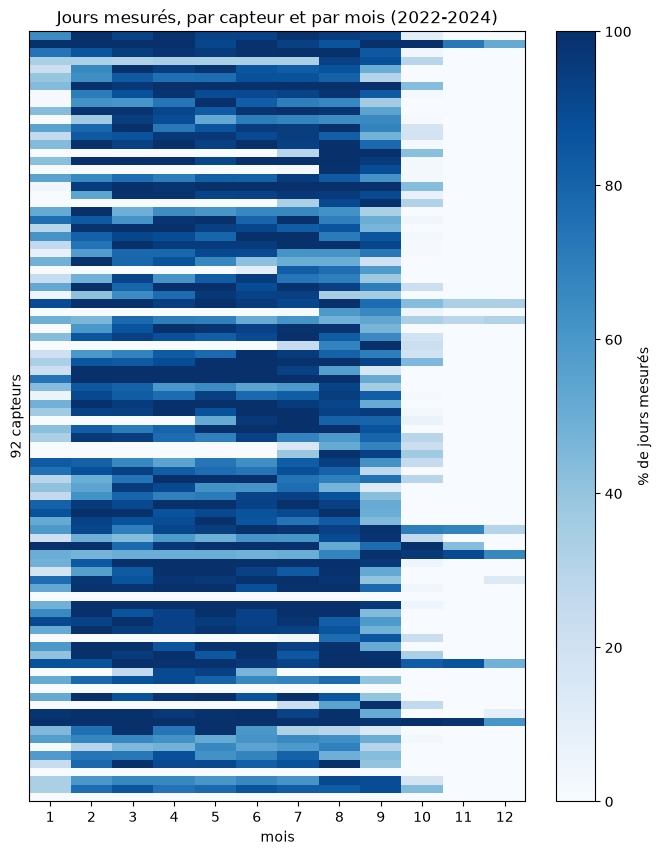

In [12]:
# mois 
pollen_jour["mois"] = pollen_jour["date"].dt.month

# part des jours mesurés, pour chaque capteur par mois
carte = pollen_jour.groupby(["station", "mois"])["mesure"].mean().unstack() * 100

plt.figure(figsize=(8, 10))
plt.imshow(carte, aspect="auto", cmap="Blues")
plt.colorbar(label="% de jours mesurés")
plt.xticks(range(12), range(1, 13))
plt.yticks([])
plt.xlabel("mois")
plt.ylabel("92 capteurs")
plt.title("Jours mesurés, par capteur et par mois (2022-2024)")
plt.show()

Les capteurs mesurent surtout de février à septembre. Au total, 45 % des jours sont sans mesure.
Quelques capteurs ont peu de mesures.
La colonne Total Taxons sera utilisée pour étudier l'impact de l'ajout des données de pollens sur notre modèle.

## 2. NaN par département et par semaine

Notre modèle travaille par département et par semaine : je fais la moyenne de chaque capteur sur la semaine, puis la moyenne des capteurs d'un même département.

In [13]:
# attribution d'une étiquette semaine à chaque jour/capteur
iso = pollen_jour["date"].dt.isocalendar()
pollen_jour["date_semaine"] = iso["year"].astype(str) + "-S" + iso["week"].astype(str).str.zfill(2)
pollen_sem = pollen_jour.groupby(["station", "date_semaine"])[["pollens"]].mean().reset_index()

# puis son département
pollen_sem["code_dept"] = pollen_sem["station"].map(lambda s: stations[s][1])
# moyenne des capteurs d'un même département
pollen_dep = pollen_sem.groupby(["code_dept", "date_semaine"])[["pollens"]].mean().reset_index()
print(pollen_dep["code_dept"].nunique(), "départements sur 96 ont au moins un capteur")

68 départements sur 96 ont au moins un capteur


In [14]:
# liste des 96 départements (merge_2)
merge = pd.read_csv("../data/final_metropole/Merge_final_2.csv", dtype={"code_dept": str})
departements = sorted(merge["code_dept"].unique())
print(len(departements), "départements")

# une ligne pour chaque département et chaque semaine
grille = []
for dep in departements:
    for s in sorted(pollen_sem["date_semaine"].unique()):
        grille.append({"code_dept": dep, "date_semaine": s})

# on ajoute les valeurs de pollen ou NaN 
base = pd.DataFrame(grille).merge(pollen_dep, on=["code_dept", "date_semaine"], how="left")

print(round(base["pollens"].isna().mean() * 100), "% des cases département x semaine sont vides")

96 départements
57 % des cases département x semaine sont vides


57 % des cases département × semaine sont vides : les 28 départements sans capteur n'ont aucune valeur, et les autres ont des trous en hiver (et quelques-uns en saison).

## 3. Trois façons de remplacer les NaN

- A. par 0
- B. par la valeur du capteur le plus proche du département, la même semaine
- C. par la médiane de tous les départements, la même semaine

S'il reste des vides (aucune valeur cette semaine-là, en hiver), je mets 0.

In [15]:
# A. par 0
pollen_A = base.copy()
pollen_A["pollens"] = pollen_A["pollens"].fillna(0)

Pour la méthode B, il faut savoir où se trouve chaque département pour calculer sa distance aux capteurs. Nos fichiers ne donnent pas cette information : je prends donc un point par département (sa ville principale).
Comme pour la table de correspondance des capteurs, c'est une tâche pratique : les coordonnées approchées de ces 96 points ont été écrites avec l'aide de Claude.

In [16]:
# coordonnées d'un point par département (ville principale), pour calculer les distances
coord_dept = {
    "01": (46.21, 5.23), "02": (49.56, 3.62), "03": (46.57, 3.33), "04": (44.09, 6.24),
    "05": (44.56, 6.08), "06": (43.7, 7.27), "07": (44.74, 4.6), "08": (49.77, 4.72),
    "09": (42.97, 1.61), "10": (48.3, 4.08), "11": (43.21, 2.35), "12": (44.35, 2.57),
    "13": (43.3, 5.37), "14": (49.18, -0.37), "15": (44.93, 2.44), "16": (45.65, 0.16),
    "17": (46.16, -1.15), "18": (47.08, 2.4), "19": (45.27, 1.77), "21": (47.32, 5.04),
    "22": (48.51, -2.76), "23": (46.17, 1.87), "24": (45.18, 0.72), "25": (47.24, 6.02),
    "26": (44.93, 4.89), "27": (49.02, 1.15), "28": (48.45, 1.49), "29": (48.0, -4.1),
    "2A": (41.93, 8.74), "2B": (42.7, 9.45), "30": (43.84, 4.36), "31": (43.6, 1.44),
    "32": (43.65, 0.59), "33": (44.84, -0.58), "34": (43.61, 3.88), "35": (48.11, -1.68),
    "36": (46.81, 1.69), "37": (47.39, 0.69), "38": (45.19, 5.72), "39": (46.67, 5.55),
    "40": (43.89, -0.5), "41": (47.59, 1.33), "42": (45.44, 4.39), "43": (45.04, 3.88),
    "44": (47.22, -1.55), "45": (47.9, 1.91), "46": (44.45, 1.44), "47": (44.2, 0.62),
    "48": (44.52, 3.5), "49": (47.47, -0.55), "50": (49.12, -1.09), "51": (48.96, 4.36),
    "52": (48.11, 5.14), "53": (48.07, -0.77), "54": (48.69, 6.18), "55": (48.77, 5.16),
    "56": (47.66, -2.76), "57": (49.12, 6.18), "58": (46.99, 3.16), "59": (50.63, 3.06),
    "60": (49.43, 2.08), "61": (48.43, 0.09), "62": (50.29, 2.78), "63": (45.78, 3.08),
    "64": (43.3, -0.37), "65": (43.23, 0.08), "66": (42.7, 2.9), "67": (48.58, 7.75),
    "68": (48.08, 7.36), "69": (45.76, 4.84), "70": (47.62, 6.15), "71": (46.31, 4.83),
    "72": (48.0, 0.2), "73": (45.56, 5.92), "74": (45.9, 6.13), "75": (48.86, 2.35),
    "76": (49.44, 1.1), "77": (48.54, 2.66), "78": (48.8, 2.13), "79": (46.32, -0.46),
    "80": (49.89, 2.3), "81": (43.93, 2.15), "82": (44.02, 1.35), "83": (43.12, 5.93),
    "84": (43.95, 4.81), "85": (46.67, -1.43), "86": (46.58, 0.34), "87": (45.83, 1.26),
    "88": (48.17, 6.45), "89": (47.8, 3.57), "90": (47.64, 6.86), "91": (48.63, 2.44),
    "92": (48.89, 2.21), "93": (48.91, 2.44), "94": (48.79, 2.46), "95": (49.04, 2.08),
}

In [17]:
# B. capteur le plus proche de chaque département
gps = gps.set_index("Stations")
# pour chaque département : distance (Pythagore) entre coordonnées ville principale et capteurs,
# on garde le capteur le plus proche, dont on prendra les valeurs quand le département n'a pas de mesure
proche = {}
for dep in coord_dept:
    lat, lon = coord_dept[dep]
    # distance entre le département et chaque capteur (Pythagore, en degrés)
    distances = {}
    for code in stations:
        nom = stations[code][0]
        distances[code] = ((gps.loc[nom, "Latitude"] - lat) ** 2 + (gps.loc[nom, "Longitude"] - lon) ** 2) ** 0.5
        
    # le capteur avec la plus petite distance
    proche[dep] = pd.Series(distances).idxmin()

# on remplit les trous avec la valeur du capteur le plus proche, la même semaine
pollen_B = base.copy()
pollen_B["station"] = pollen_B["code_dept"].map(proche)
pollen_B = pollen_B.merge(pollen_sem[["station", "date_semaine", "pollens"]], on=["station", "date_semaine"],
                          how="left", suffixes=("", "_proche"))
pollen_B["pollens"] = pollen_B["pollens"].fillna(pollen_B["pollens_proche"]).fillna(0)

In [18]:
# C. médiane de tous les départements la même semaine
pollen_C = base.copy()
# calcul la médiane des départements
mediane = pollen_C.groupby("date_semaine")["pollens"].transform("median")
pollen_C["pollens"] = pollen_C["pollens"].fillna(mediane).fillna(0)

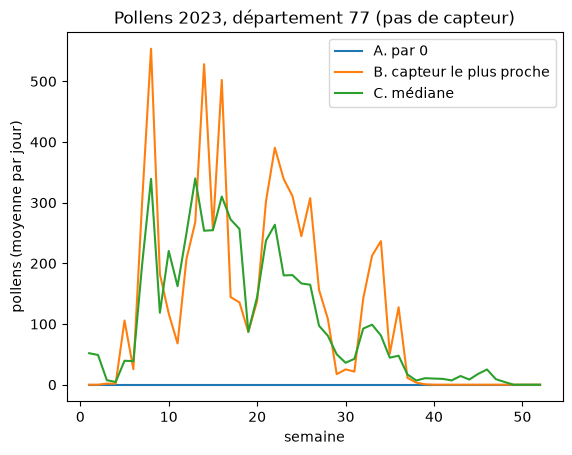

capteur le plus proche : ANTONY


In [19]:
# exemple : pollens en 2023 dans un département sans capteur (Seine et Marne)
dep = "77"
for nom, tab in [("A. par 0", pollen_A), ("B. capteur le plus proche", pollen_B), ("C. médiane", pollen_C)]:
    x = tab[(tab["code_dept"] == dep) & (tab["date_semaine"].str[:4] == "2023")]
    plt.plot(x["date_semaine"].str[-2:].astype(int), x["pollens"], label=nom)
plt.xlabel("semaine")
plt.ylabel("pollens (moyenne par jour)")
plt.title("Pollens 2023, département " + dep + " (pas de capteur)")
plt.legend()
plt.show()

print("capteur le plus proche :", proche[dep])

Trois courbes très différentes : pour ce département. Attention ce sont des valeurs remplacées, pas mesurées.

## 4. Avec ou sans pollens

Même modèle que le notebook 10 : train 2022, validation 2023, test 2024 (modèle réentraîné sur 2022-2023).

In [20]:
# données et variables du notebook 10 (Merge_final_2 déjà lu plus haut)
df = merge.copy()
cible = "TousAge_allergie_urgences"
df["annee"] = df["date_semaine"].str[:4].astype(int)
df["semaine"] = df["date_semaine"].str[-2:].astype(int)
df["sos_present"] = df["sos_present"].astype(int)
df = df.sort_values(["code_dept", "annee", "semaine"]).reset_index(drop=True)

g = df.groupby("code_dept")[cible]
df["target"] = g.shift(-1)
df["moy2_dept"] = g.transform(lambda s: s.rolling(2).mean())
df["an_dernier"] = g.shift(51)
df["sem_sin"] = np.sin(2 * np.pi * df["semaine"] / 52)
df["sem_cos"] = np.cos(2 * np.pi * df["semaine"] / 52)

cols = (["moy2_dept", "sem_sin", "sem_cos"]
        + ["temperature_kelvin", "precipitation_3h", "humidite_relative",
           "vent_vitesse", "pression_mer", "visibilite"]
        + ["As in PM10", "BaP in PM10", "Cd in PM10", "Ni in PM10", "Pb in PM10",
           "NO2", "O3", "PM10", "PM2.5", "SO2",
           "Chl in PM1", "NO3 in PM1", "NH4 in PM1", "Org in PM1", "SO4 in PM1"]
        + ["pct_urbain", "pct_cadres", "pct_prof_inter", "pct_employes", "pct_ouvriers",
           "pct_retraites", "pct_sans_activite", "pct_agriculteurs",
           "densite_generalistes", "densite_pediatres", "densite_pneumologues",
           "densite_allergologues", "densite_kines", "sos_present"]
        + ["prev_Maladie_Respi_Chronique_tsage_9",
           "prev_calc_Maladie_Respi_Chronique_0-14_9",
           "prev_calc_Maladie_Respi_Chronique_15-64_9",
           "prev_calc_Maladie_Respi_Chronique_65+_9"]
        + ["an_dernier"])

In [21]:
resultats = {}
for nom, pollen in [("sans pollens", pollen_A), ("A. par 0", pollen_A),
                    ("B. capteur le plus proche", pollen_B), ("C. médiane", pollen_C)]:
    pl = pollen[["code_dept", "date_semaine", "pollens"]].copy()
    d = df.merge(pl, on=["code_dept", "date_semaine"], how="left").dropna(subset=cols + ["pollens", "target"])

    train_val = d[d["annee"] <= 2023]
    test = d[d["annee"] == 2024]

    if nom == "sans pollens":
        liste = cols
    else:
        liste = cols + ["pollens"]

    lr = LinearRegression().fit(train_val[liste], train_val["target"])
    pred = lr.predict(test[liste])
    resultats[nom] = {"R2 test": r2_score(test["target"], pred),
                      "RMSE test": mean_squared_error(test["target"], pred) ** 0.5}

resultats = pd.DataFrame(resultats).T
resultats.round(3)

,R2 test,RMSE test
sans pollens,0.396,228.428
A. par 0,0.396,228.430
B. capteur le plus proche,0.396,228.381
C. médiane,0.396,228.428


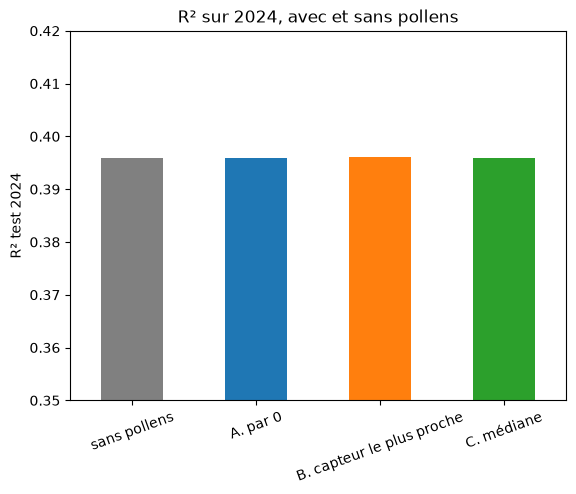

In [22]:
resultats["R2 test"].plot(kind="bar", color=["grey", "tab:blue", "tab:orange", "tab:green"])
plt.ylim(0.35, 0.42)
plt.ylabel("R² test 2024")
plt.xticks(rotation=20)
plt.title("R² sur 2024, avec et sans pollens")
plt.show()

Avec les pollens, le score ne bouge pas : R² de 0,396 et RMSE de 228 pour les trois méthodes, exactement comme sans pollens.
Aucune méthode n'apporte de gain.


## 5. Conclusion

Il manque trop de données : 57 % des cases département par semaine sont vides (28 départements sans capteur, pas de mesure en hiver).
Quelle que soit la façon de remplacer ces NaN, les pollens n'améliorent pas le modèle : ils ajoutent surtout du bruit.
On abandonne l'ajout des données de pollens.